In [50]:
import numpy as np
import pandas as pd


# Scarichiamo e leggiamo i dati del train.csv file
df = pd.read_csv("dati/train.csv")
df.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,...,4.0,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,...,0.0,0.0,0.0,0.0,Fall,46.0,64.0,Summer,0.0,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,...,2.0,1.0,1.0,28.0,Fall,38.0,54.0,Summer,2.0,0.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,...,3.0,4.0,1.0,44.0,Summer,31.0,45.0,Winter,0.0,1.0
4,0016bb22,Spring,18,1,Summer,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [51]:
print("Valori da predire:", df['sii'].unique())
print("Valori nulli nella colonna target:", df['sii'].isna().sum())
print("Tipo della classe target:", df['sii'].dtype)

# Eliminiamuo le righe con valori NaN nella colonna 'sii'
df = df.dropna(subset=['sii'])
print("Valori nulli nella colonna target dopo il drop:", df['sii'].isna().sum())

PCIAT_cols = [col for col in df.columns if 'PCIAT' in col]
df = df.drop(PCIAT_cols, axis=1)
df = df.drop(columns=['id'])

Valori da predire: [ 2.  0.  1. nan  3.]
Valori nulli nella colonna target: 1224
Tipo della classe target: float64
Valori nulli nella colonna target dopo il drop: 0


In [52]:
#                     #
# Feature Engineering #
#                     #

df = df[df['Physical-Weight'] != 0]

# Prendiamo la media tra i valori di BMI
df['Physical-BMI'] = df[['Physical-BMI', 'BIA-BIA_BMI']].mean(axis=1)
df = df.drop(columns=['BIA-BIA_BMI'], axis=1)

# Codifichiamo le varibili stagionali (10 features -> one-hot aggiungerebbe troppe colonne)
season_cols = [col for col in df.columns if 'Season' in col]
season_mapping = {
    "Summer": 0,
    "Fall": 1,
    "Winter": 2,
    "Spring": 3,
}

for col in season_cols:
    df[col] = df[col].map(season_mapping)

In [53]:
# Elimino le colonne che hanno più del 50% di valori mancanti e che non sono molto correlate con la variabile target
missing_percentage = df.isnull().mean()
columns_to_drop = missing_percentage[missing_percentage > 0.5].index
print(f"Colonne con 50%+ valori mancanti: {list(columns_to_drop)}")

correlation_with_target = df[columns_to_drop].corrwith(df['sii']).abs().sort_values(ascending=False)
print("Correlazione con la variabile target:")
print(correlation_with_target)

high_corr_features = correlation_with_target[correlation_with_target > 0.10].index  
columns_to_really_drop = set(columns_to_drop) - set(high_corr_features)

print(f"Colonne salvate: {list(high_corr_features)}")
df = df.drop(columns=columns_to_really_drop)

Colonne con 50%+ valori mancanti: ['Physical-Waist_Circumference', 'Fitness_Endurance-Season', 'Fitness_Endurance-Max_Stage', 'Fitness_Endurance-Time_Mins', 'Fitness_Endurance-Time_Sec', 'FGC-FGC_GSND', 'FGC-FGC_GSND_Zone', 'FGC-FGC_GSD', 'FGC-FGC_GSD_Zone', 'PAQ_A-Season', 'PAQ_A-PAQ_A_Total']
Correlazione con la variabile target:
Physical-Waist_Circumference    0.272885
FGC-FGC_GSD                     0.163448
FGC-FGC_GSND                    0.149495
Fitness_Endurance-Max_Stage     0.070589
Fitness_Endurance-Time_Mins     0.060628
PAQ_A-PAQ_A_Total               0.045968
PAQ_A-Season                    0.025298
FGC-FGC_GSD_Zone                0.023696
Fitness_Endurance-Time_Sec      0.008701
Fitness_Endurance-Season        0.003978
FGC-FGC_GSND_Zone               0.001667
dtype: float64
Colonne salvate: ['Physical-Waist_Circumference', 'FGC-FGC_GSD', 'FGC-FGC_GSND']


In [302]:
bins = [5, 7, 11, 13, 18, 23]
labels = ['5-7', '7-11', '11-13', '13-18', '18-23']

# Aggiungi una colonna per la fascia d'età
df["Class_Age"] = pd.cut(df["Basic_Demos-Age"], bins=bins, labels=labels, right=False)

# Ora puoi riempire i valori NaN della circonferenza vita in base a sesso e fascia d'età
df["Physical-Weight"] = df.groupby(["Basic_Demos-Sex", "Class_Age"])["Physical-Weight"]\
   .transform(lambda x: x.fillna(round(x.mean(), 2)))

df["Physical-Height"] = df.groupby(["Basic_Demos-Sex", "Class_Age"])["Physical-Height"]\
   .transform(lambda x: x.fillna(round(x.mean(), 2)))

df["Physical-Waist_Circumference"] = df.groupby(["Basic_Demos-Sex", "Class_Age"])["Physical-Waist_Circumference"]\
   .transform(lambda x: x.fillna(round(x.mean(), 2)))

# for col in df.columns:
#     if df[col].isnull().any():
#         # Step 1: imputazione con media per Sex + Class_Age
#         step1 = df.groupby(["Basic_Demos-Sex", "Class_Age"])[col].transform('mean')
        
#         # Step 2: imputazione con media solo per Sex (per chi è ancora NaN)
#         step2 = df.groupby("Basic_Demos-Sex")[col].transform('mean')

#         # Applichiamo in ordine, con round:
#         df[col] = df[col].fillna(step1).fillna(step2).round()


/var/folders/zq/gk5f556s7zq33crv9lknkrhm0000gn/T/ipykernel_86077/2361273366.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df["Physical-Weight"] = df.groupby(["Basic_Demos-Sex", "Class_Age"])["Physical-Weight"]\
/var/folders/zq/gk5f556s7zq33crv9lknkrhm0000gn/T/ipykernel_86077/2361273366.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df["Physical-Height"] = df.groupby(["Basic_Demos-Sex", "Class_Age"])["Physical-Height"]\
/var/folders/zq/gk5f556s7zq33crv9lknkrhm0000gn/T/ipykernel_86077/2361273366.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future

In [54]:
# df = df.drop(columns=['Class_Age'], axis=1)

for col in df.columns:
   #if col != 'Physical-Waist_Circumference':
   df[col].fillna(round(df[col].mean()), inplace=True)

# df['Physical-Waist_Circumference'].fillna(0.74 * df['Physical-BMI'] * (df['Physical-Height']/10), inplace=True)

df = df.astype(float)
df = df.round(2)

/var/folders/zq/gk5f556s7zq33crv9lknkrhm0000gn/T/ipykernel_95438/3225305901.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(round(df[col].mean()), inplace=True)


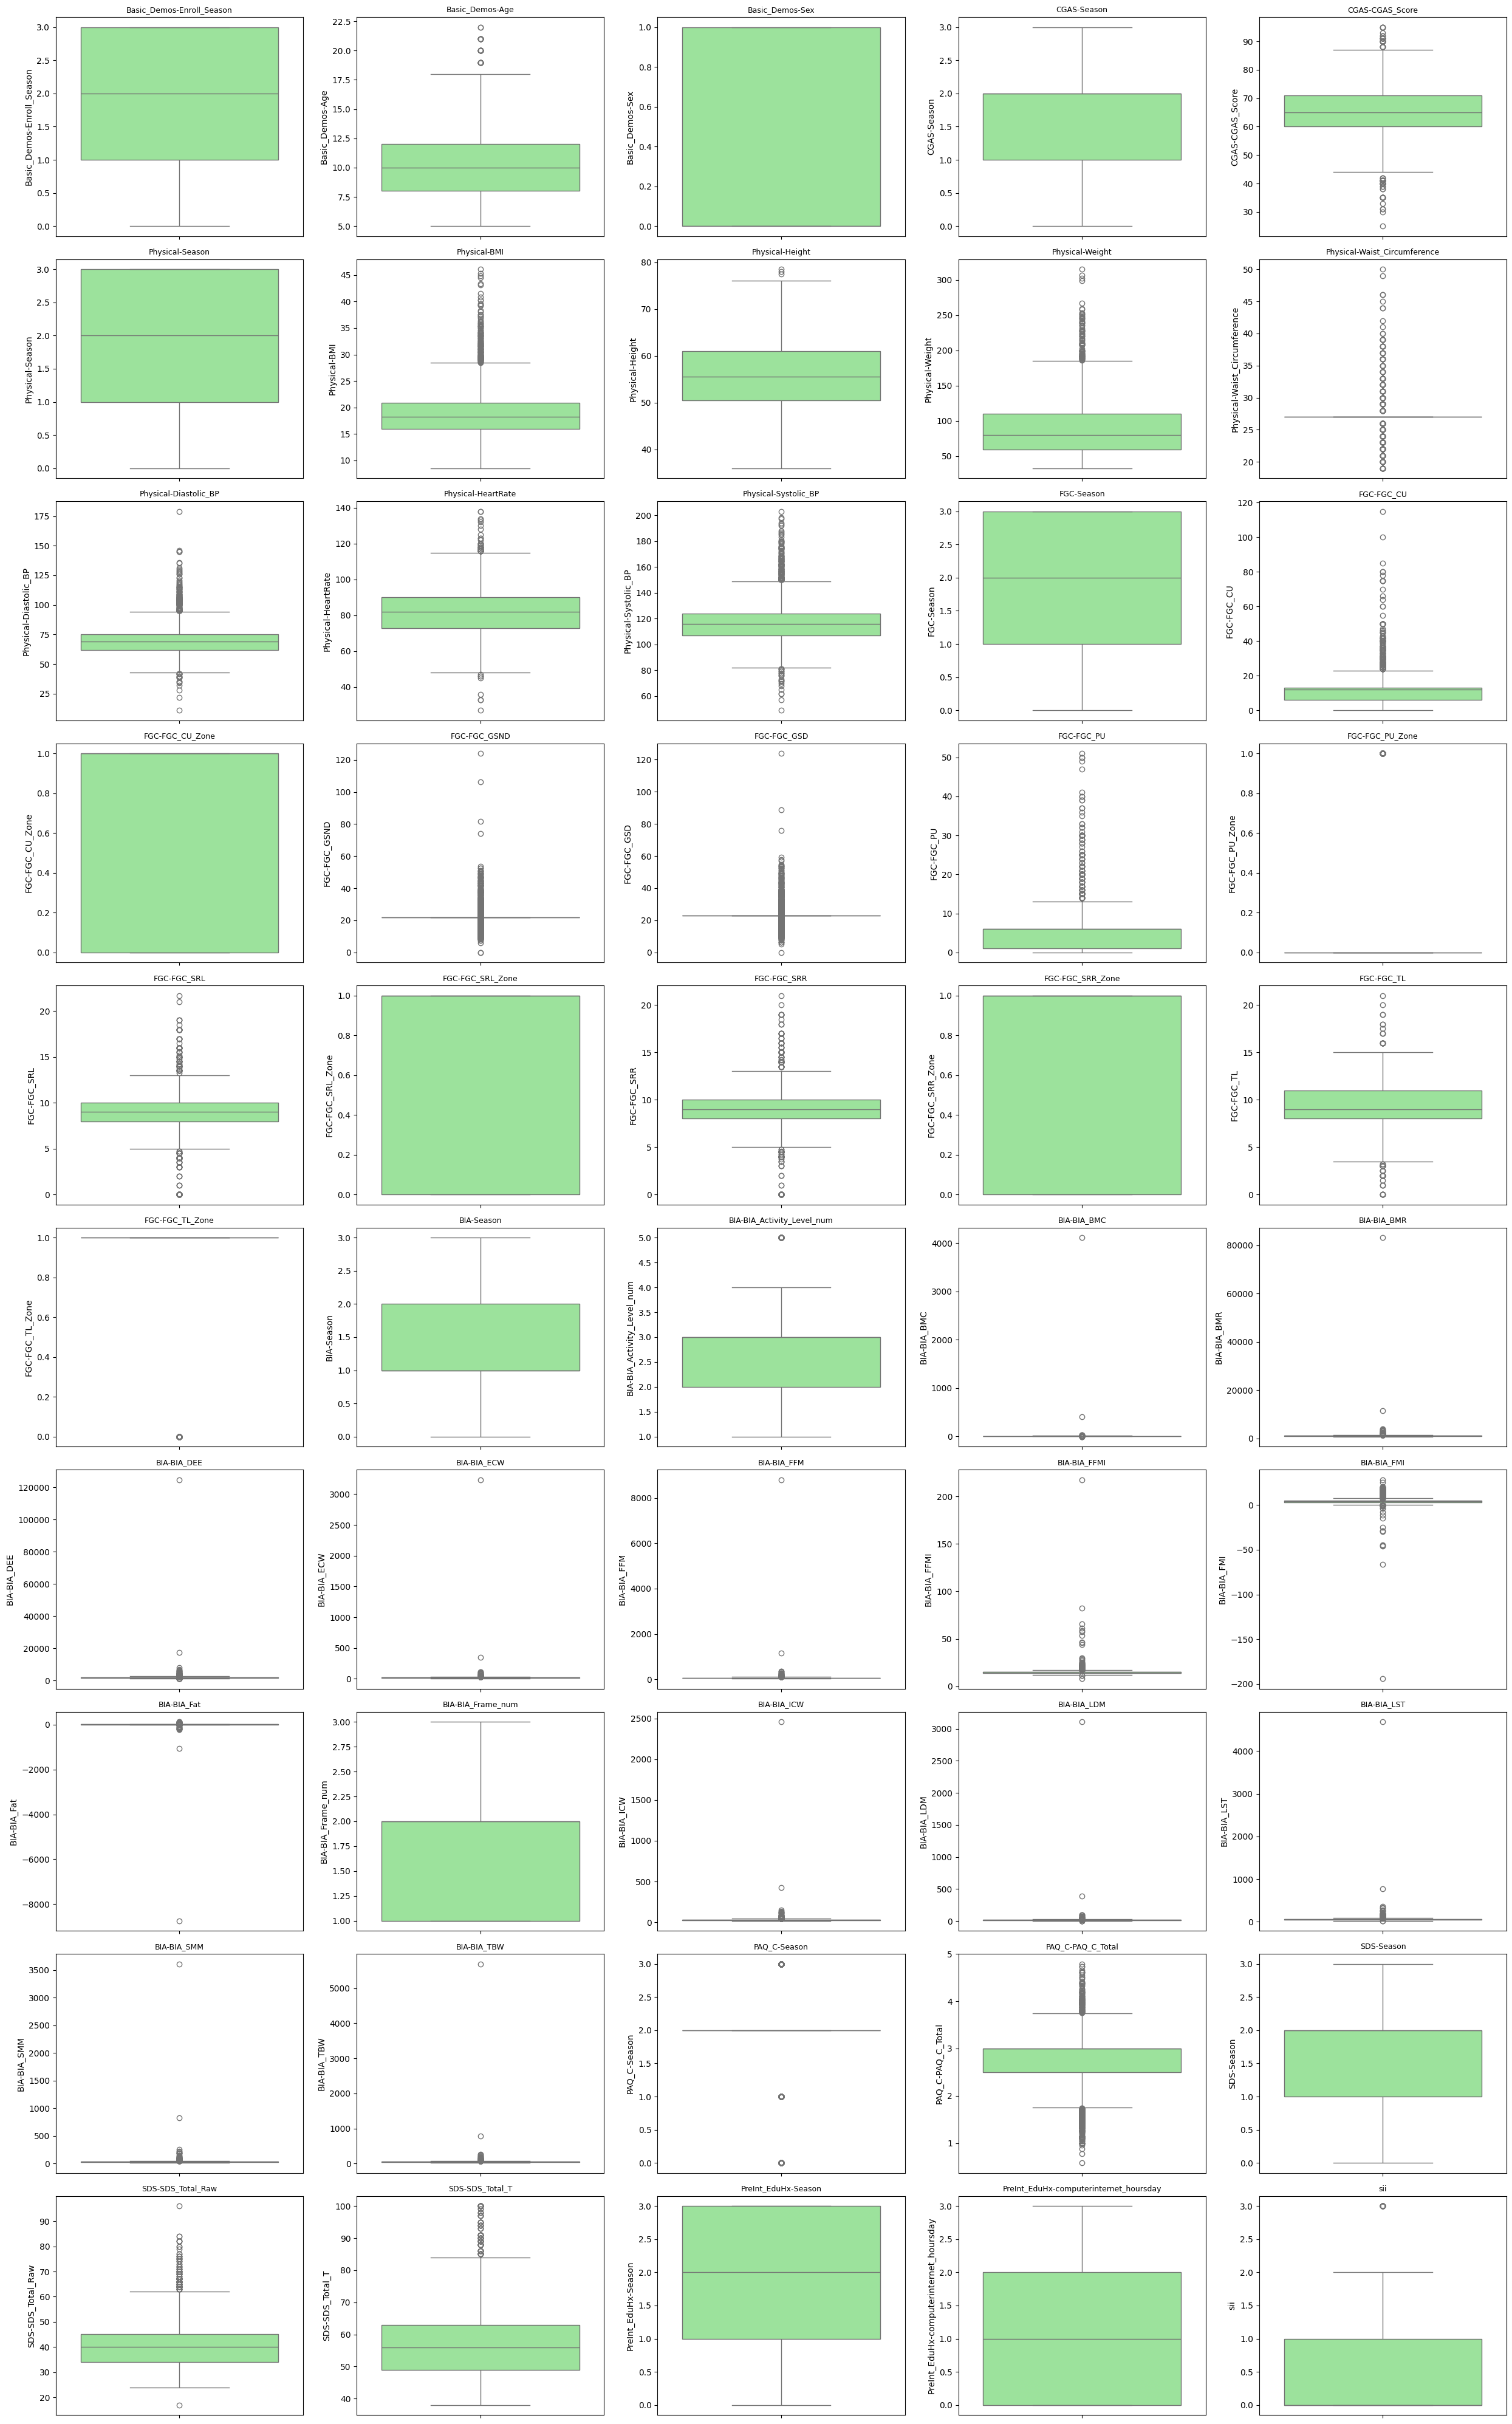

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Seleziona solo le colonne numeriche
numerical_cols = df.select_dtypes(include=['number']).columns
n_cols = len(numerical_cols)

# Imposta il numero di colonne per riga
cols_per_row = 5
n_rows = math.ceil(n_cols / cols_per_row)

# Crea la figura
plt.figure(figsize=(5 * cols_per_row, 4 * n_rows))

# Crea i boxplot uno a fianco all'altro
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(n_rows, cols_per_row, i)
    sns.boxplot(y=df[col], color="lightgreen")
    plt.title(col, fontsize=9)
    plt.tight_layout()

plt.show()


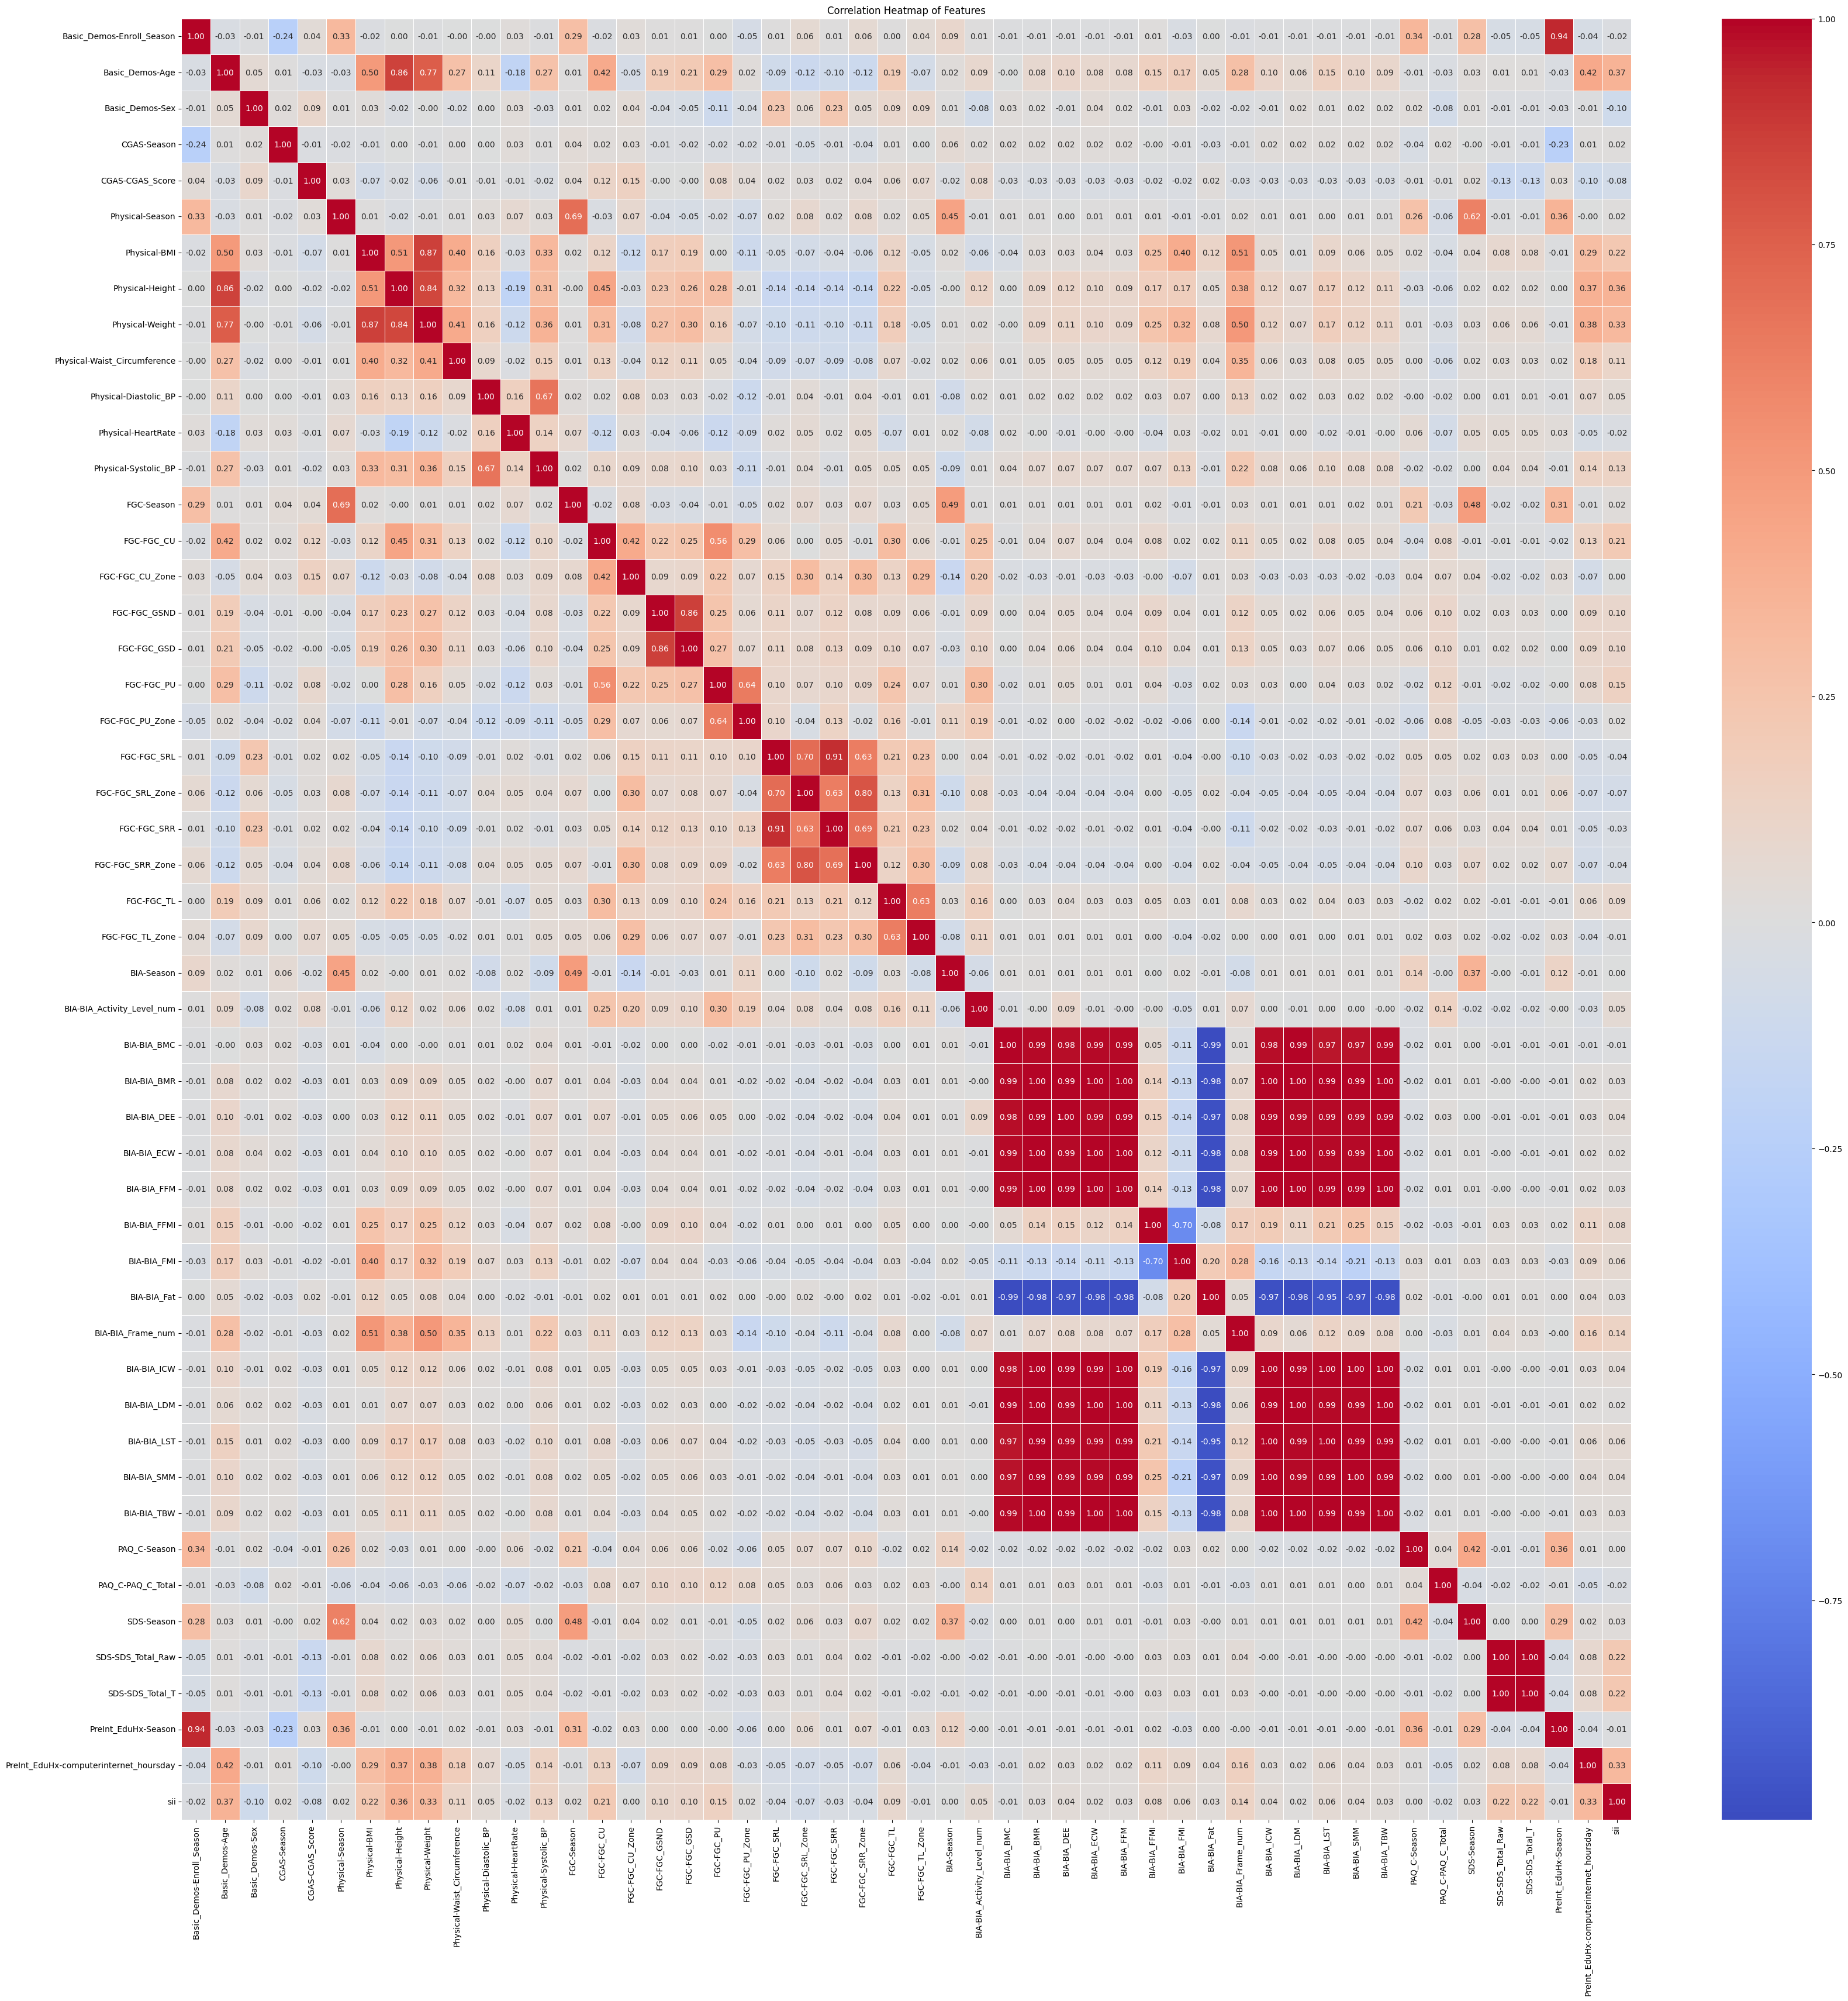

In [56]:
import seaborn as sns

# Calculate correlation matrix
corr_matrix = df.corr()

# Plot heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()


In [57]:
# Sistolica > diastolica
import pandas as pd

X = df.drop(columns=['sii'])
y = df['sii']

In [58]:
max_values = df.max()
min_values = df.min()

# Crea un nuovo DataFrame con i valori massimi e minimi
df_min_max = pd.DataFrame({
    'Colonna': df.columns,
    'Valore Minimo': min_values,
    'Valore Massimo': max_values
})

df_min_max

,Colonna,Valore Minimo,Valore Massimo
Basic_Demos-Enroll_Season,Basic_Demos-Enroll_Season,0.00,3.00
Basic_Demos-Age,Basic_Demos-Age,5.00,22.00
Basic_Demos-Sex,Basic_Demos-Sex,0.00,1.00
CGAS-Season,CGAS-Season,0.00,3.00
CGAS-CGAS_Score,CGAS-CGAS_Score,25.00,95.00
Physical-Season,Physical-Season,0.00,3.00
Physical-BMI,Physical-BMI,8.51,46.11
Physical-Height,Physical-Height,36.00,78.50
Physical-Weight,Physical-Weight,32.80,315.00
Physical-Waist_Circumference,Physical-Waist_Circumference,19.00,50.00


Feature 'Physical-Height' è fortemente correlata con: ['Basic_Demos-Age'], eliminata.
Feature 'Physical-Weight' è fortemente correlata con: ['Basic_Demos-Age', 'Physical-BMI'], eliminata.
Feature 'Physical-Waist_Circumference' è fortemente correlata con: ['Basic_Demos-Age'], eliminata.
Feature 'FGC-FGC_GSD' è fortemente correlata con: ['FGC-FGC_GSND'], eliminata.
Feature 'FGC-FGC_SRR' è fortemente correlata con: ['FGC-FGC_SRL'], eliminata.
Feature 'FGC-FGC_SRR_Zone' è fortemente correlata con: ['FGC-FGC_SRL_Zone'], eliminata.
Feature 'BIA-BIA_BMR' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_DEE' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_ECW' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_FFM' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_Fat' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_ICW' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.


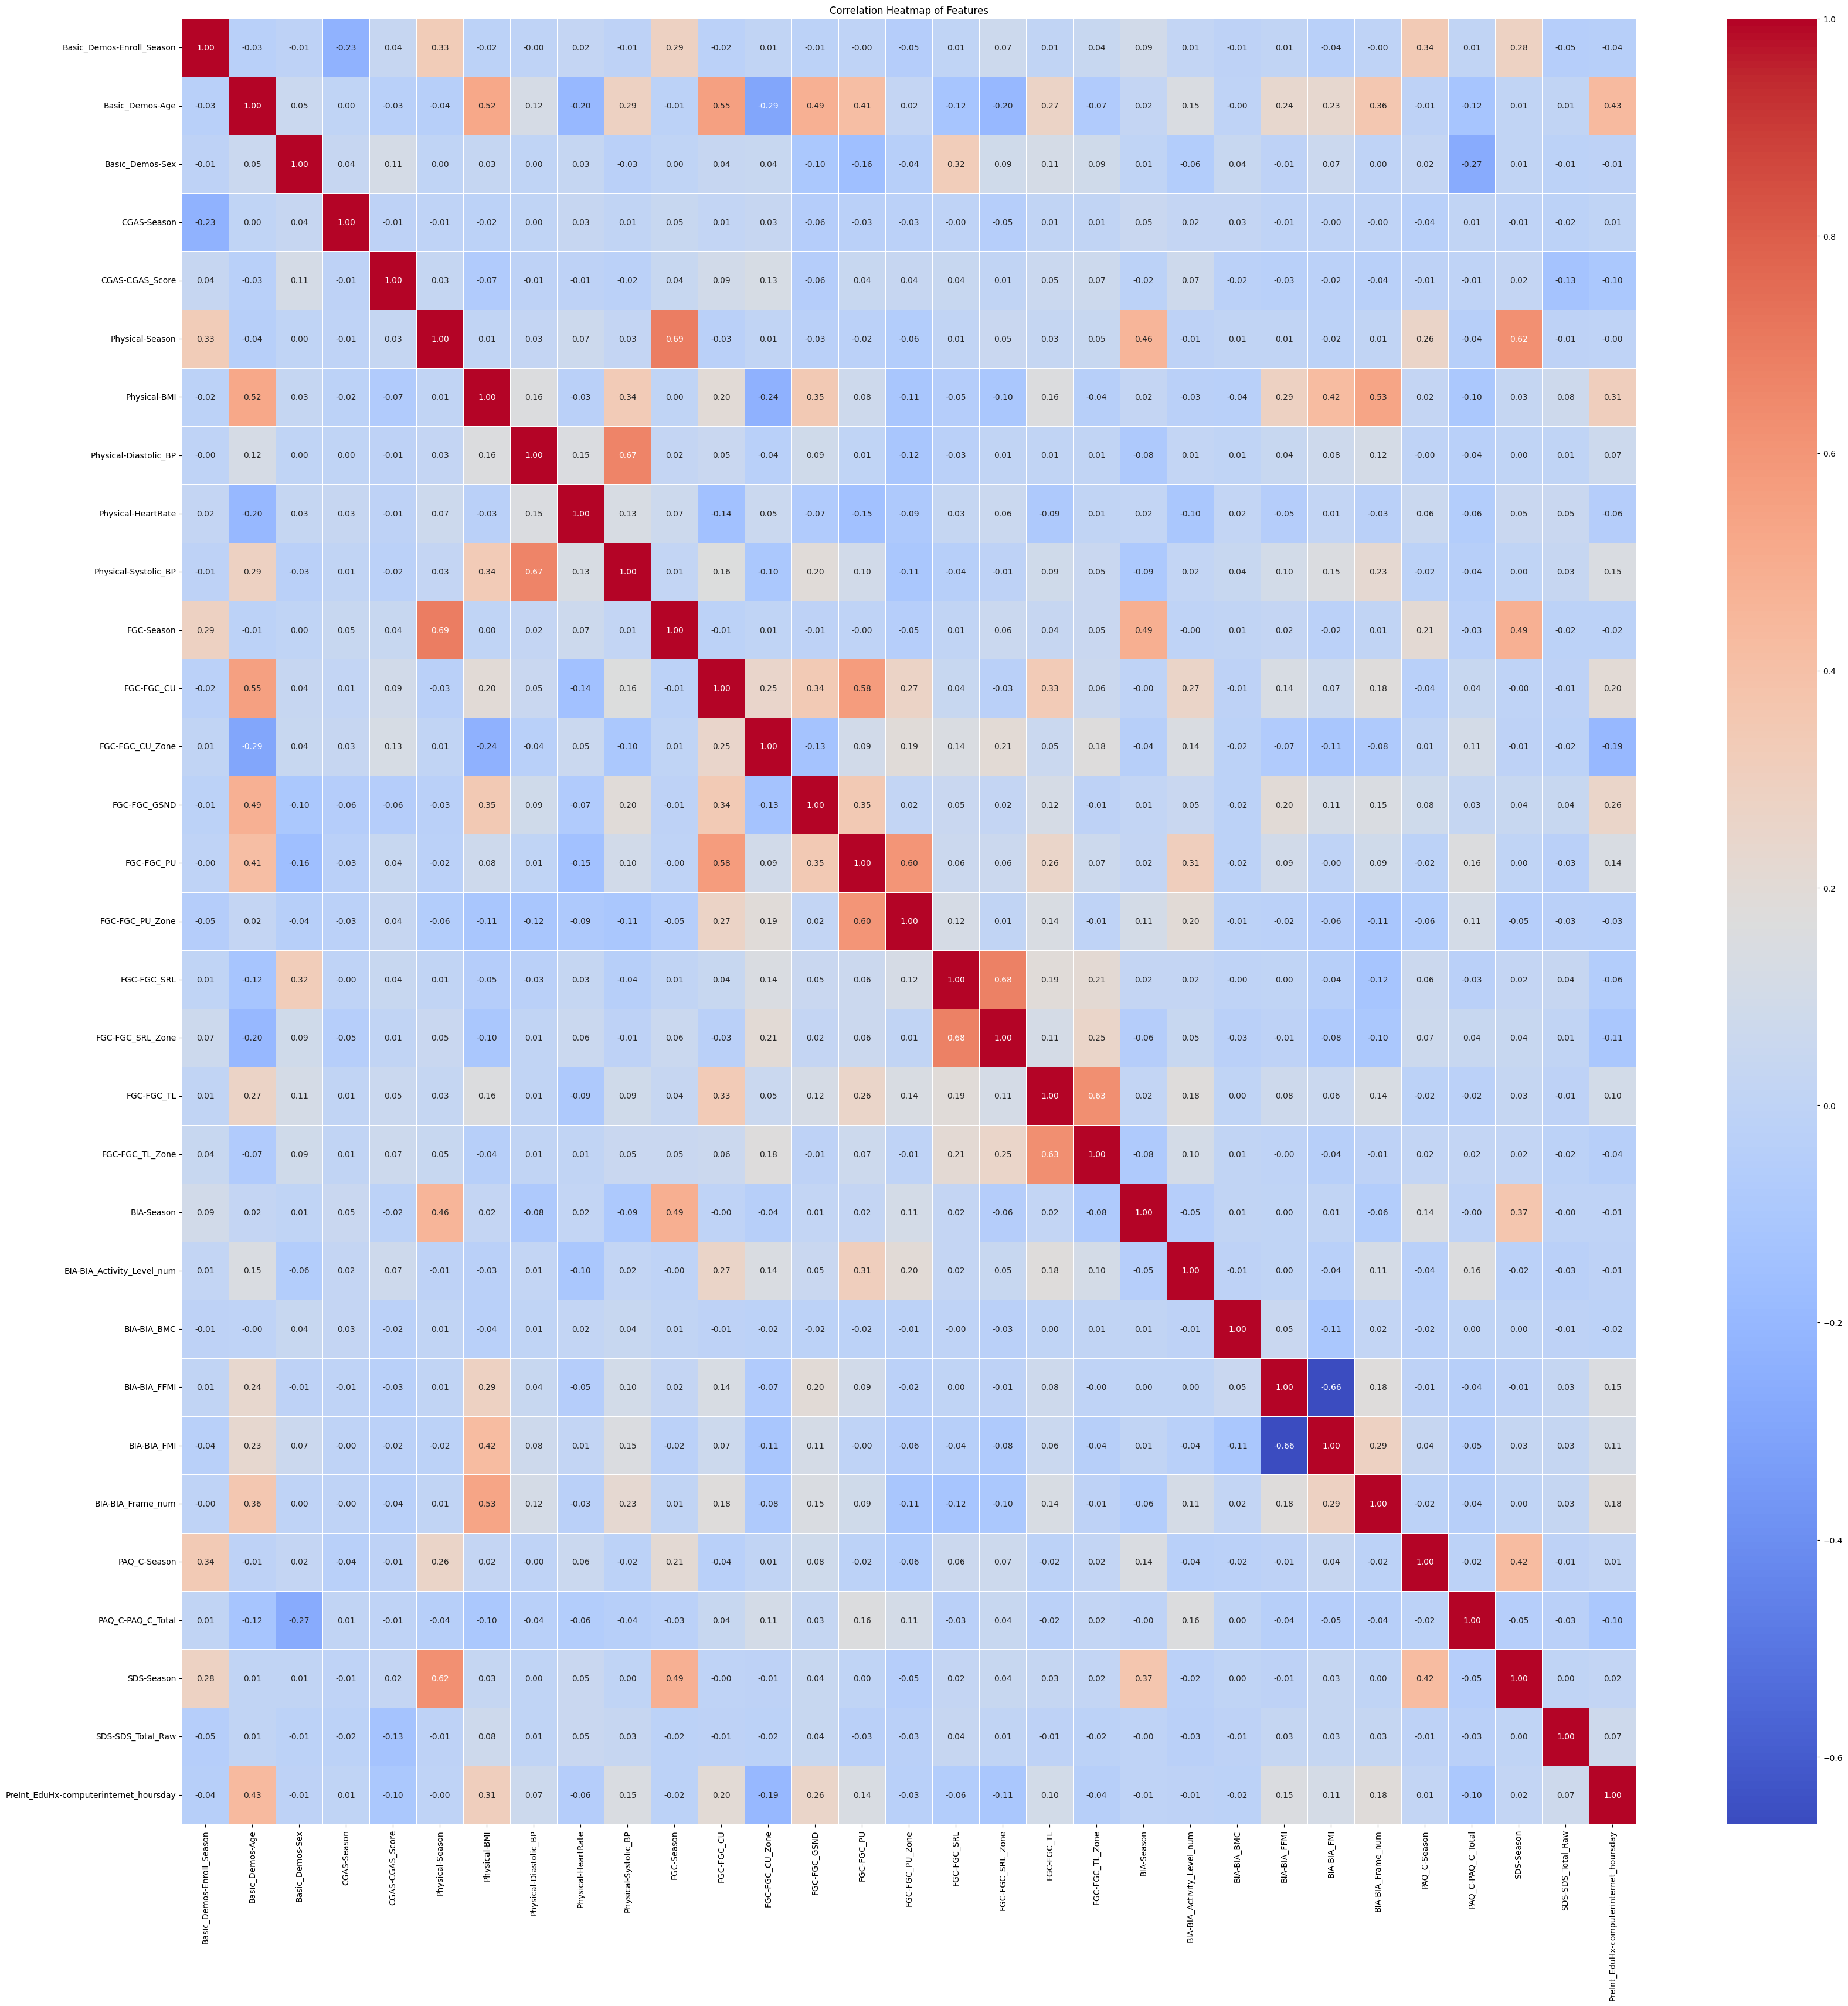

In [228]:
# Droppiamo le feature con una correlazione > di 0.7 o < di -0.7 -> Troppo correlate tra loro
import pandas as pd
# la colonna sii è derivata direttamente dalle colonne PCIAT-PCIAT_* -> non possiamo tenerle in considerazione

threshold = 0.7

while True:
    corr_matrix = X.corr()  # Ricalcola la matrice di correlazione
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))  # Mantieni solo la parte superiore

    to_drop = None
    for column in upper.columns:
        if any(abs(upper[column]) >= threshold):
            to_drop = column
            break  # Esci dal ciclo appena trovi una feature da eliminare

    if to_drop is None:
        break  # Se non ci sono più feature da eliminare, esci dal ciclo

    correlated_features = upper.index[abs(upper[to_drop]) >= threshold].tolist()
    print(f"Feature '{to_drop}' è fortemente correlata con: {correlated_features}, eliminata.")

    X = X.drop(columns=to_drop)  # Elimina la feature dal dataset

print(f"Dropped features: {to_drop}")
X.shape


import seaborn as sns

# Riguardiamo la matrice di correlazione
corr_matrix = X.corr()

# Plot heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()

In [59]:
print("X shape", X.shape)
print("y shape", y.shape)

# Contiamo quanti valori ci sono per ogni classe
# in questo modo capiamo qual è la soglia minima
# predicendo sempre la classe più frequente
print(y.value_counts(normalize=True))

from sklearn.model_selection import train_test_split

X_train80, X_test20, y_train80, y_test20 = train_test_split(X, y, test_size=0.20, random_state=42)


X shape (2684, 49)
y shape (2684,)
sii
0.0    0.581222
1.0    0.267511
2.0    0.138599
3.0    0.012668
Name: proportion, dtype: float64


In [60]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Proviamo con un albero di decisione con tutti i parametri di default

decTree = DecisionTreeClassifier(random_state=42)
decTree.fit(X_train80,y_train80)

print("Train acc:", accuracy_score(y_true = y_train80, y_pred = decTree.predict(X_train80))) # -> overfitting!
print("Test acc:", accuracy_score(y_true = y_test20,  y_pred = decTree.predict(X_test20)))

from sklearn.model_selection import cross_val_score

scores = cross_val_score(decTree, X_train80, y_train80, cv=10)
print("Accuracy media con cv=20:", scores.mean())

Train acc: 1.0
Test acc: 0.49906890130353815
Accuracy media con cv=20: 0.49230167354922844


In [61]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

#
# Modello usando un albero di decisione
# usando come stopping criteria il numero di foglie
# split: 80/20
#

best_leaves = None
best_cv_acc = 0
for max_leaves in range(2,30):
    decTree = DecisionTreeClassifier(max_leaf_nodes=max_leaves, random_state=42)

    cv_scores = cross_val_score(decTree, X_train80, y_train80, cv=20, scoring='accuracy')
    mean_cv_acc = np.mean(cv_scores)
    
    # Save the best max_leaf_nodes
    if mean_cv_acc > best_cv_acc:
        best_cv_acc = mean_cv_acc
        best_leaves = max_leaves

print(f"Il miglior numero di foglie è {best_leaves} con una cross-validation accuracy di {best_cv_acc:.3f}")

Il miglior numero di foglie è 5 con una cross-validation accuracy di 0.608


In [62]:
#
# Modello usando un albero di decisione
# usando come stopping criteria la profondità
# split: 80/20
#

bestDepth = None
best_cv_acc = 0

for max_depth in range(1, 20):
    decTree = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    cv_scores = cross_val_score(decTree, X_train80, y_train80, cv=20, scoring='accuracy')
    mean_cv_acc = np.mean(cv_scores)
    
    if mean_cv_acc > best_cv_acc:
        best_cv_acc = mean_cv_acc
        bestDepth = max_depth

print(f"Il miglior numero di profondità è {bestDepth} con una cross-validation accuracy di {best_cv_acc:.3f}")


Il miglior numero di profondità è 3 con una cross-validation accuracy di 0.604


In [63]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion': ['gini', 'entropy'],  # Keep the best criterion from RandomizedSearchCV
    'min_samples_leaf': [10, 25, 50, 100, 150, 200, 300],  # Try specific leaf sizes
    'min_impurity_decrease': [0.0, 0.01, 0.03, 0.05, 0.07, 0.1],
}

tree = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=tree, param_grid=param_grid, cv=20, scoring="accuracy", n_jobs=-1)

grid_search.fit(X_train80, y_train80)

print("Best parameters:", grid_search.best_params_)

Best parameters: {'criterion': 'entropy', 'min_impurity_decrease': 0.0, 'min_samples_leaf': 100}


In [64]:
print(grid_search.best_estimator_)
best_tree = grid_search.best_estimator_
best_tree.fit(X_train80, y_train80)

train_acc = accuracy_score(y_true=y_train80, y_pred=best_tree.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=best_tree.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(best_tree, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = best_tree.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print("Top features based on importance:")
print(importance_df.head(10))  

DecisionTreeClassifier(criterion='entropy', min_samples_leaf=100,
                       random_state=42)
Train Accuracy: 0.619
Test Accuracy: 0.598
Cross-Validation Accuracy: 0.6138 ± 0.0327
Top features based on importance:
Basic_Demos-Age                           0.447010
PreInt_EduHx-computerinternet_hoursday    0.224291
SDS-SDS_Total_T                           0.124161
FGC-FGC_GSND                              0.036998
FGC-FGC_PU                                0.031720
Physical-Weight                           0.027112
BIA-BIA_FMI                               0.024508
Physical-Height                           0.022347
BIA-BIA_SMM                               0.021569
FGC-FGC_CU                                0.017203
dtype: float64


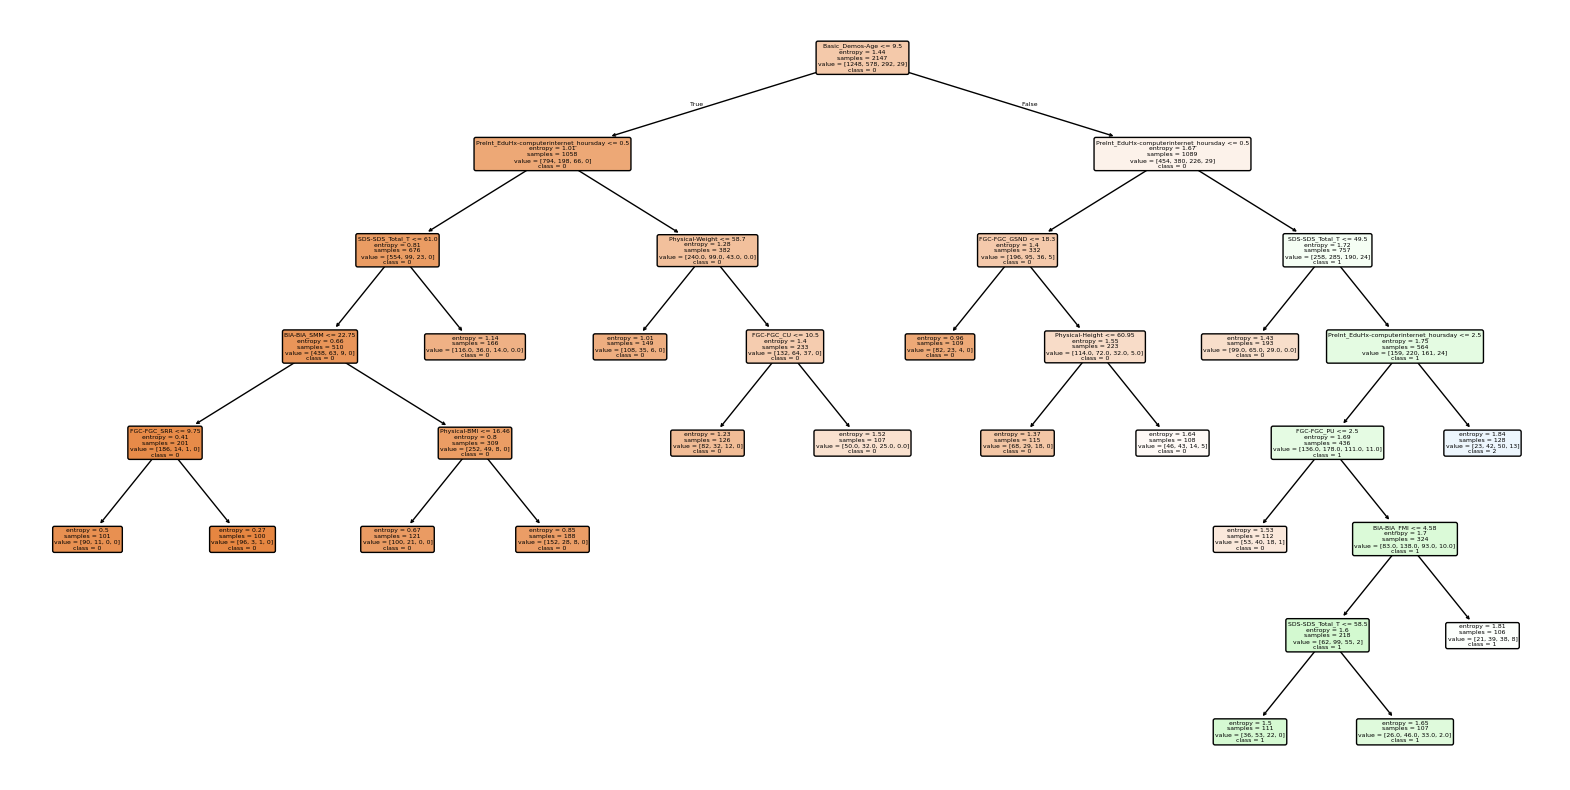

In [65]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10)) 
plot_tree(best_tree, filled=True, feature_names=X_train80.columns, class_names=["0", "1", "2", "3"], 
          rounded=True, proportion=False, precision=2)
plt.show()


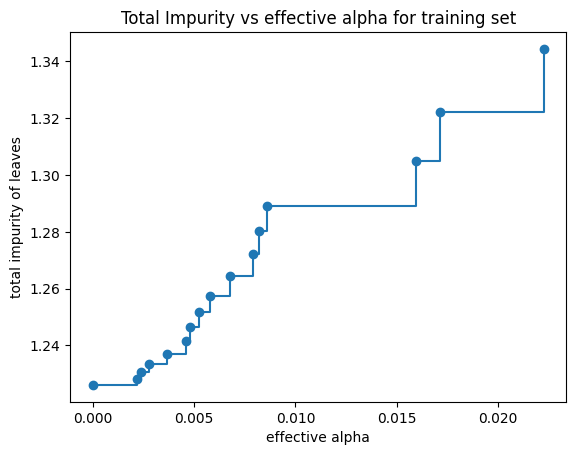

In [66]:
import matplotlib.pyplot as plt

#
# Proviamo a fare pruning usando cross-validation
# Split: 80/20
#

path = best_tree.cost_complexity_pruning_path(X_train80, y_train80)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

fig, ax = plt.subplots()
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set");

#
# Alpha vicino a 0.002 -> sembra essere un buon valore
#

In [67]:
# Costruiamo tutti gli alberi con i vari valori di ccp_alpha
ccp_alphas = ccp_alphas[:-1]
dts = []
best_params_grid = grid_search.best_params_
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ccp_alpha,
        **best_params_grid
    )
    dt.fit(X_train80, y_train80)
    dts.append(dt)

    test_acc = accuracy_score(y_true=y_test20, y_pred=dt.predict(X_test20))

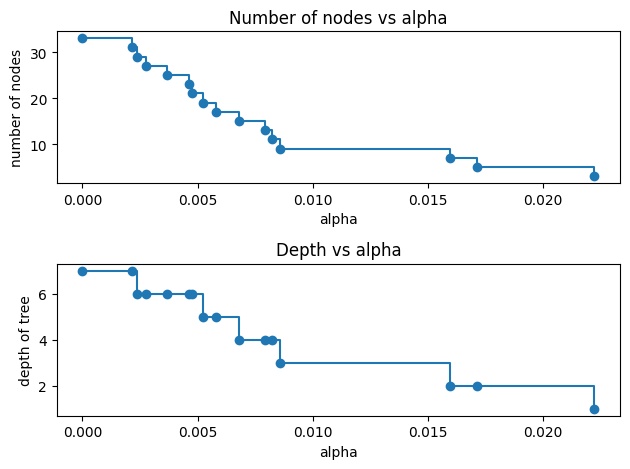

In [68]:
node_counts = [dt.tree_.node_count for dt in dts]
depth = [dt.tree_.max_depth for dt in dts]
fig, ax = plt.subplots(2, 1)
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

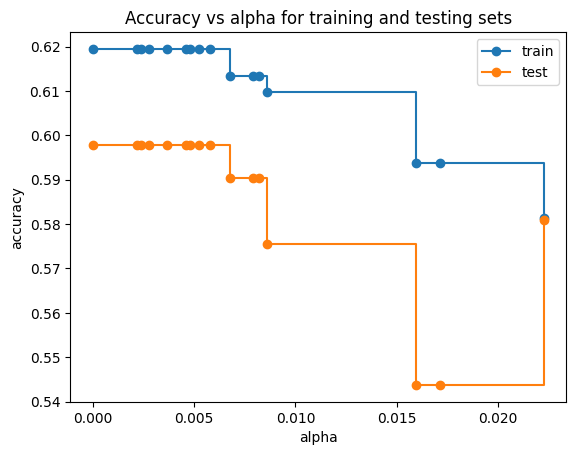

In [69]:
train_scores = [dt.score(X_train80, y_train80) for dt in dts]
test_scores = [dt.score(X_test20, y_test20) for dt in dts]

fig, ax = plt.subplots()
ax.set_xlabel("alpha")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy vs alpha for training and testing sets")
ax.plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, test_scores, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

<Axes: xlabel='alpha'>

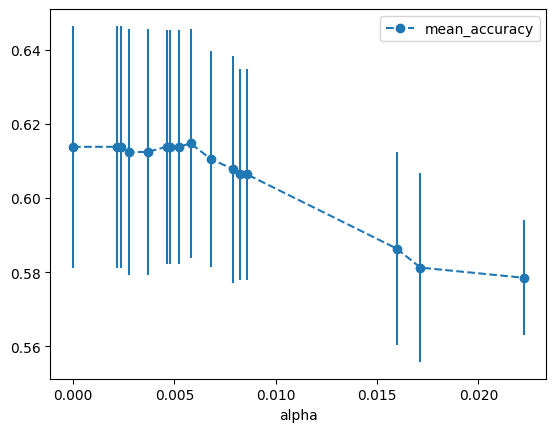

In [70]:
# Controlliamo i valori di alpha per vedere quale è più "consistente" nei dati
# vale a dire, quale valore di alpha ha la media più alta
alpha_loop_values = []
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ccp_alpha,
        **best_params_grid
    )
    scores = cross_val_score(dt, X_train80, y_train80, cv=20)
    alpha_loop_values.append([ccp_alpha, np.mean(scores), np.std(scores)])

alpha_results = pd.DataFrame(alpha_loop_values, columns=['alpha', 'mean_accuracy', 'std'])

alpha_results.plot(x='alpha', 
                   y='mean_accuracy', 
                   yerr='std', 
                   marker='o', 
                   linestyle='--')

In [71]:
# prendo il valore effettivo di alpha che ha la media più alta
subset = alpha_results[(alpha_results['alpha'] >= 0.0) 
              & (alpha_results['alpha'] < 0.010)]

ideal_alpha = subset.loc[subset['mean_accuracy'].idxmax(), 'alpha']
ideal_alpha = float(ideal_alpha)
print("Miglior valore di alpha:", ideal_alpha)

Miglior valore di alpha: 0.0057984291499175444


In [72]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

#
# Creo il modello con il valore di alpha ideale
# Split: 80/20
# Mostro la CM per vedere la distribuzione dei valori predetti
#

dt_pruned = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ideal_alpha,
        **best_params_grid
    )
dt_pruned.fit(X_train80, y_train80)
print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=dt_pruned.predict(X_train80)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=dt_pruned.predict(X_test20)))

cv_scores = cross_val_score(dt_pruned, X_train80, y_train80, cv=20, scoring="accuracy")

print(f"Cross-Validation Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Train accuracy: 0.6194690265486725
Test accuracy: 0.5977653631284916
Cross-Validation Accuracy: 0.6148 ± 0.0309


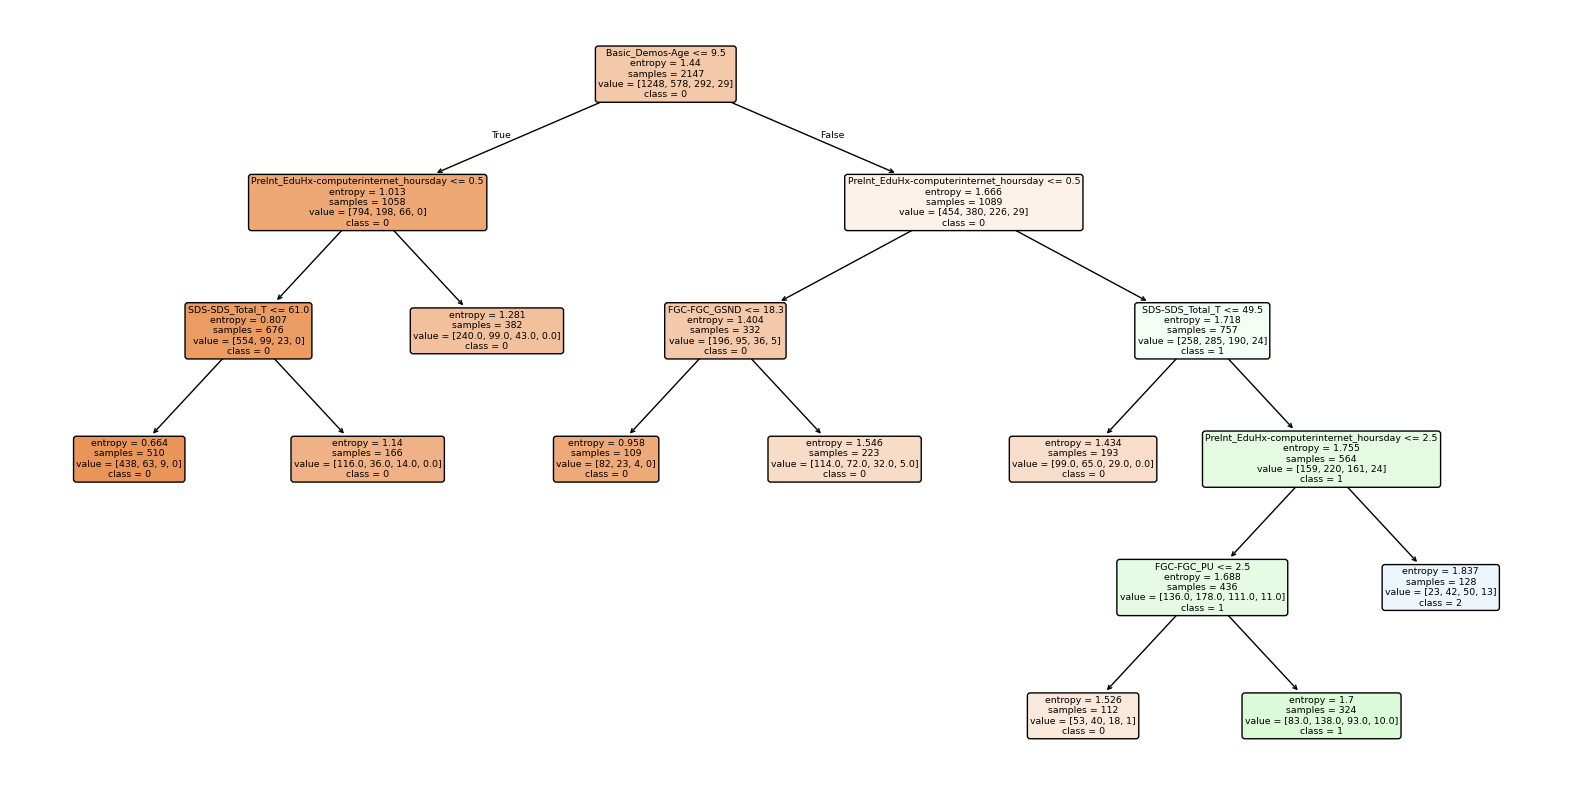

In [73]:
from sklearn.tree import plot_tree

#
# Mostro l'albero di decisione che si va' a crearea usando il valore di alpha ideale
#

plt.figure(figsize=(20,10))
plot_tree(dt_pruned, filled=True, rounded=True, feature_names=X.columns, class_names=["0", "1", "2", "3"])
plt.show()

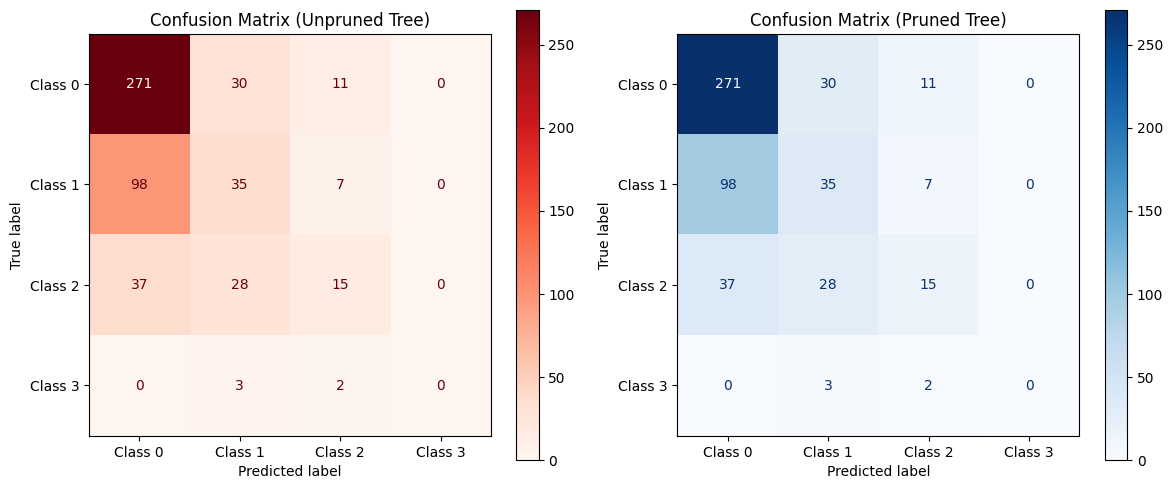

In [74]:
# Mostra la matrice di confusione con etichette
cm_unpruned = confusion_matrix(y_test20, best_tree.predict(X_test20))
cm_pruned = confusion_matrix(y_test20, dt_pruned.predict(X_test20))

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Unpruned tree confusion matrix
disp_unpruned = ConfusionMatrixDisplay(confusion_matrix=cm_unpruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_unpruned.plot(ax=axes[0], cmap="Reds")
axes[0].set_title("Confusion Matrix (Unpruned Tree)")

# Pruned tree confusion matrix
disp_pruned = ConfusionMatrixDisplay(confusion_matrix=cm_pruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_pruned.plot(ax=axes[1], cmap="Blues")
axes[1].set_title("Confusion Matrix (Pruned Tree)")

# Adjust layout
plt.tight_layout()
plt.show()

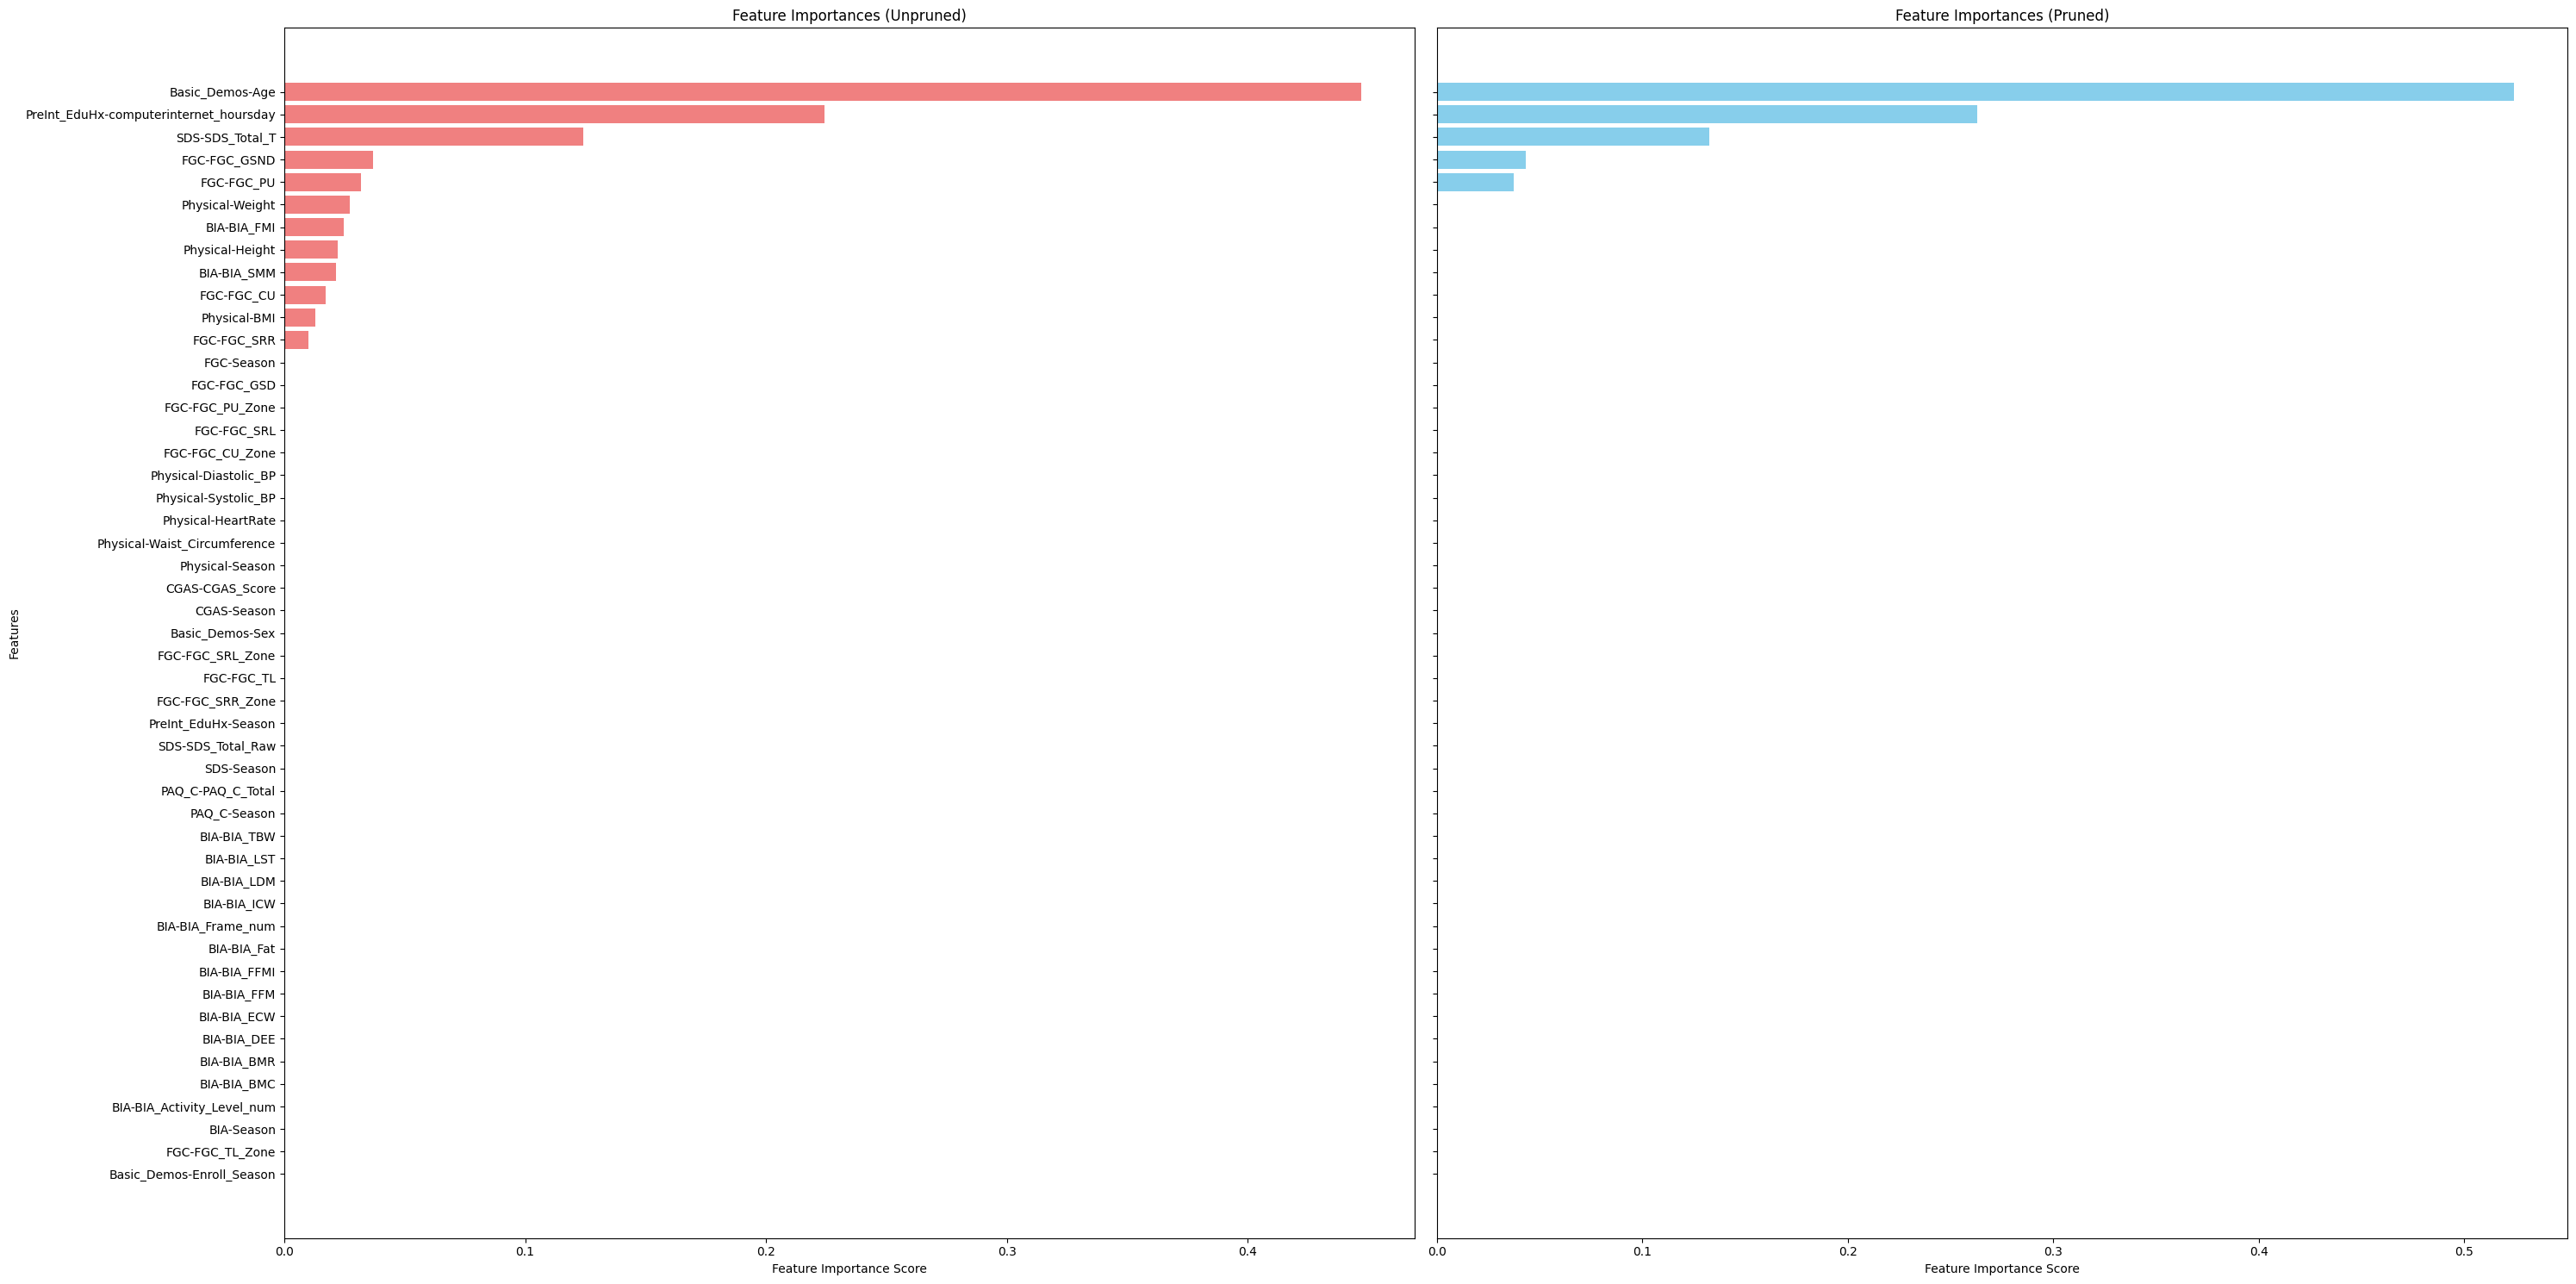

In [75]:
import numpy as np
import matplotlib.pyplot as plt

# Feature importances for both trees
importances_unpruned = best_tree.feature_importances_
importances_pruned = dt_pruned.feature_importances_

# Sort feature importances
sorted_idx_unpruned = np.argsort(importances_unpruned)[::-1]
sorted_idx_pruned = np.argsort(importances_pruned)[::-1]

sorted_features_unpruned = X_train80.columns[sorted_idx_unpruned]
sorted_features_pruned = X_train80.columns[sorted_idx_pruned]

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(30, 15), sharey=True)

# Unpruned tree plot
axes[0].barh(sorted_features_unpruned, importances_unpruned[sorted_idx_unpruned], color='lightcoral')
axes[0].set_xlabel("Feature Importance Score")
axes[0].set_ylabel("Features")
axes[0].set_title("Feature Importances (Unpruned)")
axes[0].invert_yaxis()

# Pruned tree plot
axes[1].barh(sorted_features_pruned, importances_pruned[sorted_idx_pruned], color='skyblue')
axes[1].set_xlabel("Feature Importance Score")
axes[1].set_title("Feature Importances (Pruned)")

# Show the combined plot
plt.tight_layout()
plt.show()


In [76]:
from sklearn.feature_selection import RFECV

rfecv = RFECV(
    estimator=dt_pruned,
    step=1,
    cv=20,
    scoring="accuracy",
    min_features_to_select=1,
    n_jobs=2,
)
rfecv.fit(X_train80, y_train80)

print(f"Optimal number of features: {rfecv.n_features_}")

Optimal number of features: 7


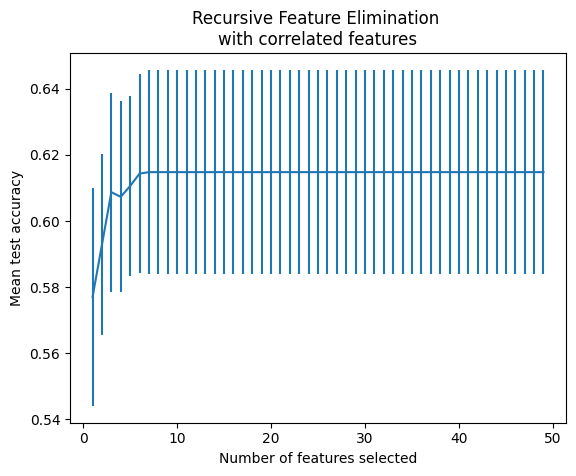

In [77]:
import matplotlib.pyplot as plt
import pandas as pd

cv_results = pd.DataFrame(rfecv.cv_results_)
plt.figure()
plt.xlabel("Number of features selected")
plt.ylabel("Mean test accuracy")
plt.errorbar(
    x=cv_results["n_features"],
    y=cv_results["mean_test_score"],
    yerr=cv_results["std_test_score"],
)
plt.title("Recursive Feature Elimination \nwith correlated features")
plt.show()

In [78]:
selected_features = X.columns[rfecv.support_]
print("Feature selezionate:", list(selected_features))

X_train_rfecv = X_train80[selected_features]
X_test_rfecv = X_test20[selected_features]

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Creiamo un nuovo Decision Tree
best_tree_rfecv = DecisionTreeClassifier(
        **best_params_grid,
        random_state=42 )

# Addestriamo il modello con le feature selezionate
best_tree_rfecv.fit(X_train_rfecv, y_train80)

# Previsioni sul test set ridotto
y_pred_rfecv = best_tree_rfecv.predict(X_test_rfecv)

# Numero di fold per la cross-validation (es. 5)
cv_folds = 20

# Eseguiamo la cross-validation
cv_scores = cross_val_score(best_tree_rfecv, X_train_rfecv[selected_features], y_train80, cv=cv_folds, scoring='accuracy')

# Stampiamo il risultato medio e la deviazione standard
print(f"Accuratezza media con cross-validation: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Feature selezionate: ['Basic_Demos-Age', 'Physical-Weight', 'FGC-FGC_GSND', 'FGC-FGC_PU', 'SDS-SDS_Total_Raw', 'PreInt_EduHx-Season', 'PreInt_EduHx-computerinternet_hoursday']
Accuratezza media con cross-validation: 0.6190 ± 0.0291


In [ ]:
from sklearn.ensemble import BaggingClassifier

maxScore = -1
bestEstimators = -1
for i in range(1, 31):
   bagged_dt = BaggingClassifier(estimator=best_tree_rfecv, n_estimators=i, random_state=42)
   cv_scores = cross_val_score(bagged_dt, X_train_rfecv, y_train80, cv=5, scoring='accuracy')
   mean_cv_score = cv_scores.mean()  # Media dell'accuratezza nei fold
   
   if mean_cv_score > maxScore:
       maxScore = mean_cv_score
       bestEstimators = i

# Una volta trovato il migliore n_estimators, allena il modello finale
bestDt_bagging = BaggingClassifier(estimator=best_tree_rfecv, n_estimators=bestEstimators, random_state=42)
bestDt_bagging.fit(X_train_rfecv, y_train80)

print("bestEstimators:", bestEstimators)
print("Accuracy: {:.3f}".format(accuracy_score(y_true=y_test20, y_pred=bestDt_bagging.predict(X_test_rfecv))))

cv_scores = cross_val_score(bestDt_bagging, X_train_rfecv, y_train80, cv=20, scoring='accuracy')

print(f"Accuracy media: {cv_scores.mean()}")
print(f"Standard Deviation: {cv_scores.std()}")


bestEstimators: 10
Accuracy: 0.581
Accuracy media: 0.6049844236760125
Standard Deviation: 0.03242521904520226


Error/Bias/Variance at the last iteration: [0.69655493 0.63006983 0.0664851 ]


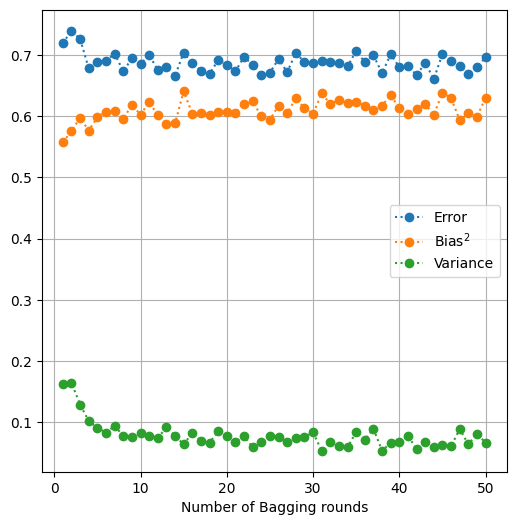

In [594]:
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

N_TESTS = 20
stats = np.array([])
bags = range(1,51)
for l in bags:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train80, y_train80, n_samples=int(0.67*len(y_train80)) )

        # train a decision tree classifier
        dt = DecisionTreeClassifier(
                min_samples_leaf=int(best_params_grid['min_samples_leaf']),
                criterion=best_params_grid['criterion'],
                random_state=42
            )
        bagged_dt = BaggingClassifier(estimator=dt, n_estimators=l, random_state=42)
        bagged_dt.fit(Xs,ys)
        
        y_pred = bagged_dt.predict(X_test20)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias     = (y_test20-np.mean(y_preds,axis=1))**2
    dt_variance = np.var(y_preds,axis=1)
    dt_error = (y_preds - y_test20.to_numpy().reshape(-1, 1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats

fig, ax = plt.subplots(figsize=(6,6))

ax.plot(bags,stats[0,:], 'o:', label='Error')
ax.plot(bags,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(bags,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Bagging rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

In [595]:
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(best_tree, n_estimators=10, random_state=42)

adaboost.fit(X_train80,y_train80)
print ("Accuracy:", accuracy_score(y_true=y_test20, y_pred=adaboost.predict(X_test20) ))

Accuracy: 0.5325884543761639


Error/Bias/Variance at the last iteration: [0.79590317 0.46146182 0.33444134]


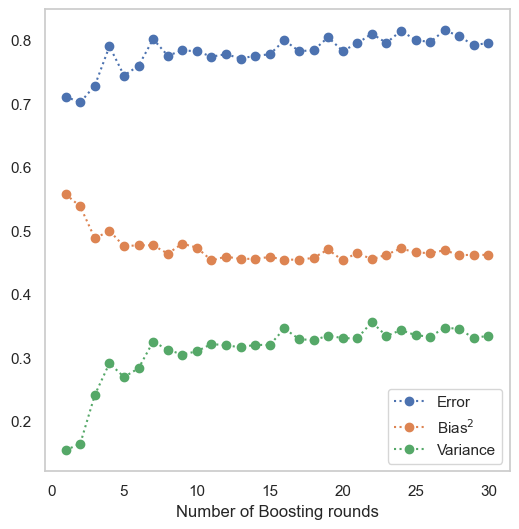

In [425]:
from sklearn.utils import resample
from sklearn.ensemble import AdaBoostClassifier

N_TESTS = 20
stats = np.array([])
boosts = range(1,31)
for l in boosts:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train80, y_train80, n_samples=int(0.67*len(y_train80)) )

        # train a decision tree classifier
        dt = DecisionTreeClassifier(
                min_samples_leaf=int(best_params_grid['min_samples_leaf']),
                criterion=best_params_grid['criterion'],
                random_state=42
            )
        adaboost = AdaBoostClassifier(estimator=dt, n_estimators=l, random_state=42)
        adaboost.fit(Xs,ys)
        
        y_pred = adaboost.predict(X_test20)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias     = (y_test20 - np.mean(y_preds, axis=1))**2
    dt_variance = np.var(y_preds, axis=1)
    dt_error    = (y_preds - y_test20.to_numpy().reshape(-1,1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats
    
fig, ax = plt.subplots(figsize=(6,6))

ax.plot(boosts,stats[0,:], 'o:', label='Error')
ax.plot(boosts,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(boosts,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Boosting rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

In [597]:
X = df.drop(columns=['sii'])
y = df['sii']
X.shape, y.shape

((2684, 80), (2684,))

In [598]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [599]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
accuracy_rf = accuracy_score(y_test, rf.predict(X_test))

print(f"Random Forest - Test Accuracy: {accuracy_rf:.3f}")


Random Forest - Test Accuracy: 0.587


In [600]:
param_grid = {
    'n_estimators': [100, 150, 250],
   'min_samples_leaf': [1, 2, 5, 10, 50],
   'oob_score': [True],
}

cv = StratifiedKFold(5)
rf = RandomForestClassifier(random_state=42)
Grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, 
                           cv=cv, n_jobs=-1, verbose=0, scoring='accuracy')
Grid_search.fit(X_train, y_train)

print("Best Parameters from Grid Search:", Grid_search.best_params_)

best_grid_rf = Grid_search.best_estimator_
test_accuracy = accuracy_score(y_test, best_grid_rf.predict(X_test))
print(f"Random Forest - Test Accuracy (after Grid Search): {test_accuracy:.3f}")


Best Parameters from Grid Search: {'min_samples_leaf': 5, 'n_estimators': 150, 'oob_score': True}
Random Forest - Test Accuracy (after Grid Search): 0.583


In [601]:
print(Grid_search.best_score_)
print(best_grid_rf.oob_score_)

0.6087450533962162
0.6059618071727992
